# 03 - Task 3: characterising the faulty conditions

**Brief:** *analysis and characterisation of the faulty conditions that could potentially affect the
system in service.*

Five faults were emulated at increasing severity (41 recordings):

| Code | Fault | How it is emulated | Settings |
|---|---|---|---|
| F1 | Clogged filter | DPV1 in series with the filter closes | 10-80 % travel |
| F2 | Degraded pump | DPV2 bleeds pump discharge back to the tank (lost delivery) | 20-100 % |
| F3 | Shut-off valve stuck mid-range | DPV3 in series with the valve closes | 10-80 % |
| F4 | Leaking pipe | DPV4 opens a leak between the valve and the nozzle | 20-90 % |
| F5 | Clogged injector | DPV5 in series with the nozzle closes | 10-80 % |

The notebook moves from what each sensor does, to why (the hydraulics), to how well each fault can be
detected and told apart, and ends with the effect the recording schedule has on all of it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fueltwin import baseline, config, diagnosis as dg, features, hydraulics as hy, plotting as pl, pump

pl.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
w = features.load_windows(1.0)
runs = features.run_means(w)
runs["severity"] = w.groupby("run_id", sort=False)["severity"].first().to_numpy()
FAULTS = list(config.FAULTS)
MEAS = ["Q", "P1", "P2", "P3", "P4", "P5"]
base = baseline.HealthyBaseline.fit(w, MEAS + ["dP_filter", "dP_pump", "dP_valve", "dP_nozzle", "fpr"])
hc_mean = base.mean

## 1. What each sensor does as each fault grows

Change from the healthy mean (run averages). The grey band is the healthy envelope from notebook 02
(+/- 4 sd), which is tiny at this scale.

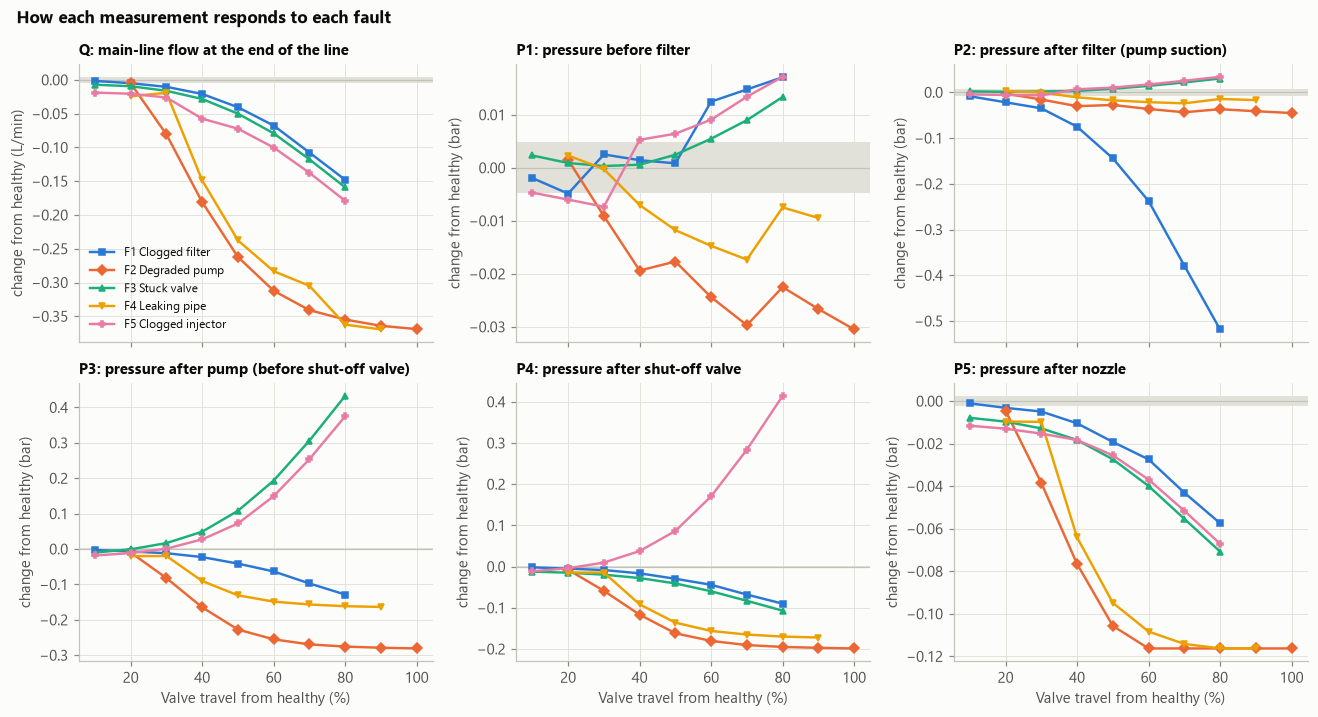

In [2]:
units = {"Q": "L/min", **{p: "bar" for p in MEAS[1:]}}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.6), sharex=True)
for ax, m in zip(axes.flat, MEAS):
    band = 4 * base.sd_total[m]
    ax.axhspan(-band, band, color=pl.GRID, lw=0)
    ax.axhline(0, color=pl.AXIS, lw=0.8)
    for f in FAULTS:
        r = runs[runs["condition"] == f].sort_values("severity")
        ax.plot(r["severity"], r[m] - hc_mean[m], color=pl.CONDITION_COLORS[f], marker=pl.CONDITION_MARKERS[f],
                ms=4.5, lw=1.6, label=f"{f} {config.CONDITION_NAMES[f]}")
    ax.set_title(f"{m}: {config.SENSORS[m].lower()}", fontsize=9.5)
    ax.set_ylabel(f"change from healthy ({units[m]})")
for ax in axes[1]:
    ax.set_xlabel("Valve travel from healthy (%)")
axes[0, 0].legend(loc="lower left", fontsize=8)
fig.suptitle("How each measurement responds to each fault", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
pl.save(fig, "03_sensor_response")
plt.show()

**Observations**

* **Every fault lowers the delivered flow Q**, so Q alone detects but cannot isolate.
* **Clogged filter (F1)** is the only fault that drives the pump suction pressure P2 sharply down
  (to 0.35 bar abs at 80 %) while P1 rises slightly: the pump pulls harder against a blocked inlet.
  Downstream pressures fall only modestly, so the system keeps working until the filter is badly
  blocked, the "tricky, easy to miss" behaviour Bardakis (2019) describes.
* **Stuck valve (F3) and clogged injector (F5)** are both blockages downstream of the pump: P3 rises
  and flow falls. They differ only at P4, the sensor between them: P4 falls for F3 (the restriction is
  upstream of it) and rises for F5 (downstream of it).
* **Degraded pump (F2) and leak (F4)** both lower every downstream pressure and the flow. The leak's
  first two settings (20 % and 30 %) change nothing measurable: the valve passes no flow until about
  35-40 % travel. F2 at 20 % is similarly close to healthy. These three recordings are labelled faulty
  but are physically healthy, which matters when classifiers are scored (notebook 04).
* Above about 60 % travel the pump-bypass and leak curves flatten: once the bypass valve is wide open,
  further travel adds little.

## 2. Signatures compared with the lecture's expectation

The lecture's diagnostic table (Diagnostic Trees, page 2) predicts an arrow for every fault and
sensor. Below, the direction measured in this data at low and high severity, with matches marked.

In [3]:
EXPECTED = {  # Q, P1, P2, P3, P4, P5 (Diagnostic Trees.pdf, page 2)
    "F1": [-1, +1, -1, -1, -1, -1], "F2": [-1, -1, -1, -1, -1, -1], "F3": [-1, +1, +1, +1, -1, -1],
    "F4": [-1, -1, -1, -1, -1, -1], "F5": [-1, +1, +1, +1, +1, -1],
}
rows = []
for f in FAULTS:
    r = runs[runs["condition"] == f].sort_values("severity")
    for level, row in [("low", r.iloc[1]), ("high", r.iloc[-1])]:
        z = (row[MEAS] - hc_mean[MEAS]) / base.sd_total[MEAS]
        sign = np.where(z > 4, 1, np.where(z < -4, -1, 0))
        rows.append({"fault": f, "level": f"{level} ({row['severity']:g} %)",
                     **{m: ("+" if s > 0 else "-" if s < 0 else "0") + (" ok" if s == e else (" x" if s != 0 else " ~"))
                        for m, s, e in zip(MEAS, sign, EXPECTED[f])}})
sig = pd.DataFrame(rows).set_index(["fault", "level"])
sig.to_csv(config.TABLE_DIR / "03_signature_vs_lecture.csv")
sig

Q    P1    P2    P3    P4    P5
fault level                                           
F1    low (20 %)    - ok   - x  - ok  - ok  - ok  - ok
      high (80 %)   - ok  + ok  - ok  - ok  - ok  - ok
F2    low (30 %)    - ok  - ok  - ok  - ok  - ok  - ok
      high (100 %)  - ok  - ok  - ok  - ok  - ok  - ok
F3    low (20 %)    - ok   0 ~   0 ~   0 ~  - ok  - ok
      high (80 %)   - ok  + ok  + ok  + ok  - ok  - ok
F4    low (30 %)    - ok   0 ~   0 ~  - ok  - ok  - ok
      high (90 %)   - ok  - ok  - ok  - ok  - ok  - ok
F5    low (20 %)    - ok   - x   0 ~   - x   - x  - ok
      high (80 %)   - ok  + ok  + ok  + ok  + ok  - ok

`+`/`-` = measured direction beyond the healthy envelope, `0` = inside it; `ok` = matches the lecture
table, `x` = opposite direction, `~` = no measurable change where one was expected.

The lecture table holds for the strong signals but differs in the details, and those details are
physical, not noise:

* **P1 falls at low severity for F1 and F5** although the lecture expects it to rise. P1 is an
  absolute pressure that also tracks the main-tank level, which kept falling through the day
  (notebook 02), so at small severities the level change outweighs the fault.
* **At 20 % the clogged injector (F5) lowers P3 and P4** where the lecture expects both to rise. F5
  was recorded last (15:43-16:11); by then the pump delivered less than in the morning (section 6),
  and that drift outweighs the small restriction. By 80 % the expected rise is clear.
* Several "small variation" arrows of the lecture are inside the healthy envelope at mild severity
  (marked `~`).

## 3. When does each fault become visible?

The smallest valve travel at which at least one measurement leaves the healthy envelope, and which
measurement it is.

In [4]:
det = []
for f in FAULTS:
    r = runs[runs["condition"] == f].sort_values("severity")
    for _, row in r.iterrows():
        z = (row[MEAS + ["dP_filter", "dP_valve", "dP_nozzle"]] - hc_mean[MEAS + ["dP_filter", "dP_valve", "dP_nozzle"]]) \
            / base.sd_total[MEAS + ["dP_filter", "dP_valve", "dP_nozzle"]]
        out = z[np.abs(z) > 4]
        if len(out):
            det.append({"fault": f, "first setting outside envelope (%)": row["severity"],
                        "clock": row["clock"].strftime("%H:%M"),
                        "variables outside (largest first)": ", ".join(out.abs().sort_values(ascending=False).index[:4]),
                        "largest |z|": float(out.abs().max())})
            break
pd.DataFrame(det)

,fault,first setting outside envelope (%),clock,variables outside (largest first),largest |z|
0,F1,10.0,10:04,"P2, dP_filter",4.708
1,F2,20.0,11:05,"P4, P3, P5, dP_valve",11.457
2,F3,10.0,14:30,"P4, P5, P3, dP_nozzle",18.133
3,F4,20.0,15:02,"P3, P4, Q, dP_valve",23.392
4,F5,10.0,15:43,"dP_valve, P3, P5, P4",22.243


Taken at face value every fault is "detected" at its very first setting, including the leak at 20 %
that has no hydraulic effect at all. That is the healthy envelope being too narrow for afternoon data,
not sensitivity: the envelope describes five minutes in the morning. Detection limits only mean
something once the day-scale drift is handled (section 6 and notebook 06).

## 4. The hydraulics behind the signatures

Each pipe section has a pressure-flow characteristic. Plotting each section's pressure drop against the
measured flow shows which faults move along the healthy characteristic (the section is healthy, only
the flow changed) and which leave it (the section itself changed, or it carries flow the meter never
sees).

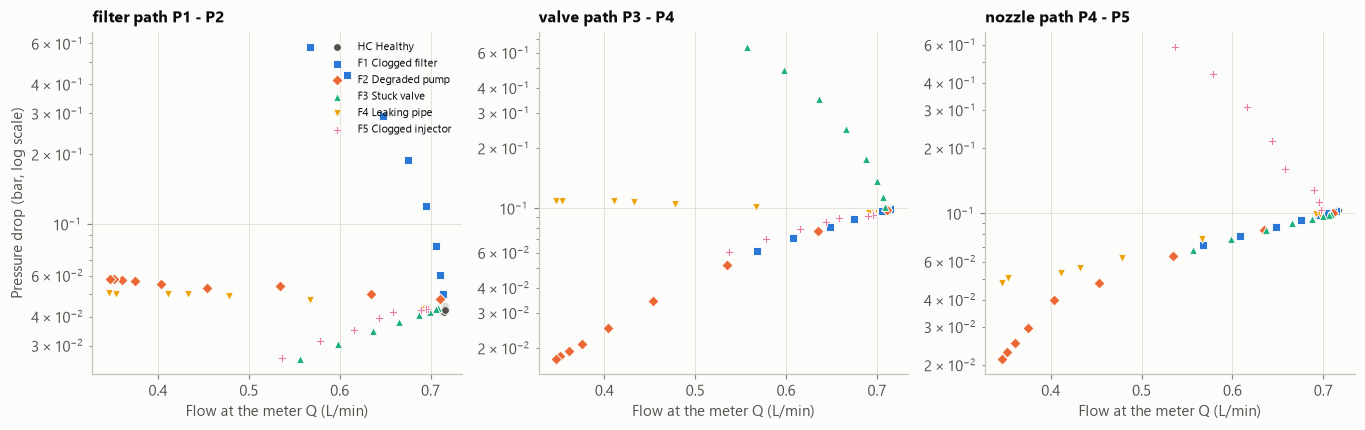

In [5]:
sect = [("dP_filter", "filter path P1 - P2"), ("dP_valve", "valve path P3 - P4"), ("dP_nozzle", "nozzle path P4 - P5")]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4))
for ax, (col, title) in zip(axes, sect):
    for f in config.CONDITIONS:
        r = runs[runs["condition"] == f]
        ax.scatter(r["Q"], r[col], s=26, color=pl.CONDITION_COLORS[f], marker=pl.CONDITION_MARKERS[f],
                   label=f"{f} {config.CONDITION_NAMES[f]}", edgecolor=pl.SURFACE, linewidth=0.6, zorder=3)
    ax.set_yscale("log")
    ax.set_xlabel("Flow at the meter Q (L/min)")
    ax.set_title(title)
axes[0].set_ylabel("Pressure drop (bar, log scale)")
axes[0].legend(fontsize=7.5, loc="upper right")
fig.tight_layout()
pl.save(fig, "03_section_characteristics")
plt.show()

* **Nozzle path**: every fault except F5 lies on one curve (the nozzle is healthy, only the flow
  changes); F5 climbs off it.
* **Valve path**: F1, F2 and F5 lie on one curve; F3 climbs off it, and so does **F4**, because the
  leak flow passes through the valve before escaping, so the valve carries more than the meter
  reports.
* **Filter path**: F3 and F5 lie on the healthy curve; F1 climbs steeply; **F2 and F4 also climb**,
  because the pump draws extra flow through the filter to feed the bypass or the leak.

That pattern is enough to separate all five faults, which the lecture tree cannot (its F1/F2/F4
ambiguity group). It is turned into four residuals: one per section, plus a pump residual that
measures how much of the pump's output never reaches the meter. Every law is fitted on windows where
that section is known to be healthy, and when a fault is scored **all of its own recordings are left
out of the fit** (see `fueltwin/hydraulics.py`).

In [6]:
R, models = hy.lofo_residuals(w)
wr = pd.concat([w[["run_id", "condition", "severity"]], R], axis=1)
res_runs = wr.groupby("run_id", sort=False).agg(condition=("condition", "first"), severity=("severity", "first"),
                                                **{c: (c, "mean") for c in R.columns})
laws = pd.DataFrame({k: {**{f"{s} k": l.k for s, l in m.sections.items()},
                         **{f"{s} n": l.n for s, l in m.sections.items()},
                         "pump Q at 0 bar": m.pump.q0, "pump slope (L/min/bar)": m.pump.slope,
                         **{f"limit {c}": v for c, v in m.thresholds.items()}}
                     for k, m in models.items()}).T
laws.index.name = "fault left out of the fit"
laws.to_csv(config.TABLE_DIR / "03_section_laws.csv")
laws.round(4)

,filter k,valve k,nozzle k,filter n,valve n,nozzle n,pump Q at 0 bar,pump slope (L/min/bar),limit r_filter,limit r_pump,limit r_valve,limit r_nozzle
fault left out of the fit,,,,,,,,,,,,
F1,0.080,0.207,0.158,1.776,2.136,1.340,0.900,-0.425,0.133,0.089,0.070,0.136
F2,0.107,0.182,0.154,2.310,1.804,1.257,0.907,-0.434,0.243,0.054,0.087,0.111
F3,0.108,0.205,0.160,2.220,2.124,1.349,0.954,-0.534,0.367,0.049,0.038,0.085
F4,0.107,0.205,0.179,2.310,2.124,1.665,0.907,-0.434,0.243,0.054,0.038,0.051
F5,0.118,0.214,0.159,2.544,2.276,1.354,0.897,-0.397,0.199,0.022,0.034,0.128
all,0.107,0.205,0.159,2.310,2.124,1.354,0.907,-0.434,0.243,0.054,0.038,0.128


Fitted exponents sit between 1.3 and 2.5: the flow is in the transitional regime, neither the linear
(laminar) nor the square (fully turbulent orifice) law. The limits (4 robust sd of each residual on
its calibration windows) are 2-14 % for the pump, valve and nozzle residuals and 13-37 % for the
filter, whose small pressure drop (0.04 bar) is the noisiest.

Residuals for every recording, expressed as multiples of their limit (|e| > 1 = beyond limit):

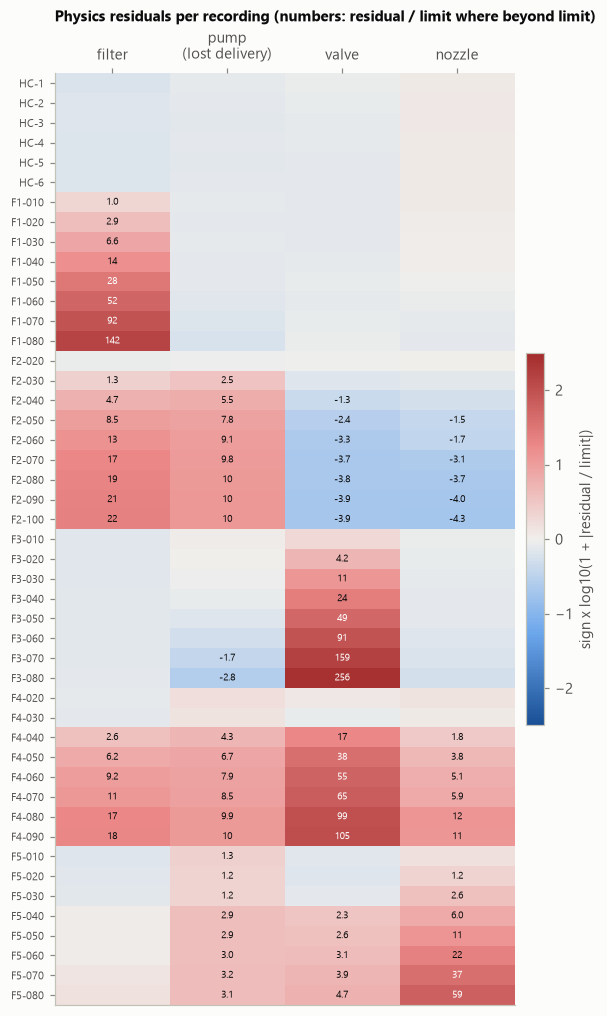

In [7]:
E = res_runs[[c for c in res_runs if c.startswith("e_")]]
order = res_runs.index
fig, ax = plt.subplots(figsize=(6.5, 11))
show = np.sign(E) * np.log10(1 + np.abs(E))
im = ax.imshow(show.to_numpy(), aspect="auto", cmap=pl.DIVERGING, vmin=-2.5, vmax=2.5)
ax.set_yticks(range(len(order)), order, fontsize=7.5)
ax.set_xticks(range(4), ["filter", "pump\n(lost delivery)", "valve", "nozzle"])
ax.xaxis.tick_top()
for i in range(len(order)):
    for j in range(4):
        v = E.iloc[i, j]
        if abs(v) >= 1:
            ax.text(j, i, f"{v:.0f}" if abs(v) >= 10 else f"{v:.1f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(show.iloc[i, j]) > 1.4 else pl.INK)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.4, pad=0.02)
cb.set_label("sign x log10(1 + |residual / limit|)")
ax.set_title("Physics residuals per recording (numbers: residual / limit where beyond limit)", pad=34, fontsize=9.5)
pl.save(fig, "03_residual_heatmap")
plt.show()

The structure predicted from the schematic appears in the data:

| | filter | pump | valve | nozzle |
|---|---|---|---|---|
| F1 | **+** | 0 | 0 | 0 |
| F2 | **+** | **+** | 0 or - | 0 or - |
| F3 | 0 | 0 or - | **+** | 0 |
| F4 | **+** | **+** | **+** | (+) |
| F5 | (+) | (+) | (+) | **+** |

The small (+) entries for F5 and the negative valve/nozzle residuals at high F2 severity are model
limits: power laws fitted at one flow range are extrapolated to much lower flows, and P5 is clipped at
zero in the strongest F2/F4 settings (notebook 01). They do not change which residual dominates.

## 5. Degradation paths on the pump map

The pump decides the system's operating point, so plotting every recording on the pump's
pressure-flow plane shows each fault as a path (Bardakis, 2019, used the same view).

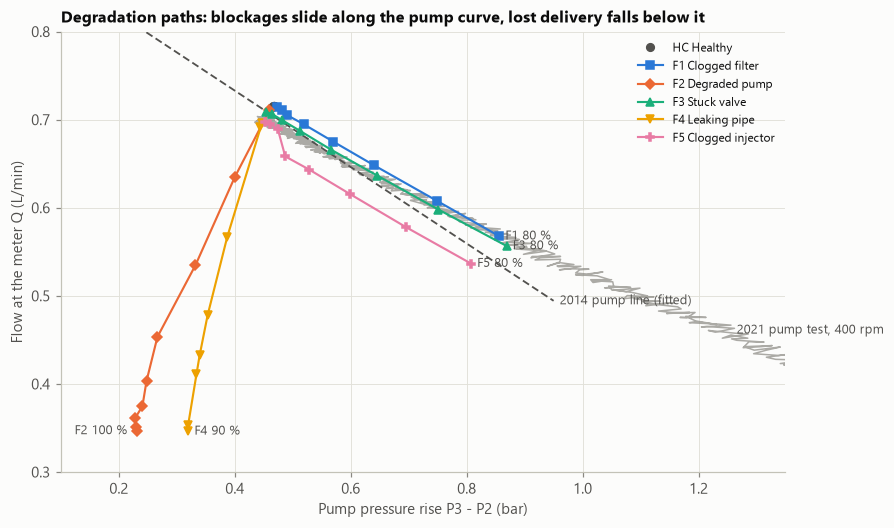

In [8]:
pc = pump.load_campaign("initial")
p400 = pc[pc["nominal_rpm"] == 400]
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.plot(p400["dP_pump"], p400["Q"], color=pl.MUTED, lw=1, alpha=0.7)
pl.label_end(ax, 1.25, float(np.interp(1.25, p400["dP_pump"].sort_values(), p400.sort_values("dP_pump")["Q"])),
             "2021 pump test, 400 rpm", dx=6)
dpg = np.linspace(0.2, 0.95, 50)
ax.plot(dpg, models["all"].pump.q(dpg), color=pl.INK_2, lw=1.2, ls=(0, (4, 2)))
pl.label_end(ax, 0.95, models["all"].pump.q(0.95), "2014 pump line (fitted)")
for f in config.CONDITIONS:
    r = runs[runs["condition"] == f].sort_values("severity")
    ax.plot(r["dP_pump"], r["Q"], color=pl.CONDITION_COLORS[f], marker=pl.CONDITION_MARKERS[f], ms=5,
            lw=1.4 if f != "HC" else 0, label=f"{f} {config.CONDITION_NAMES[f]}")
    if f != "HC":
        last = r.iloc[-1]
        if f == "F2":
            pl.label_end(ax, last["dP_pump"], last["Q"], f"{f} {last['severity']:g} %", dx=-6, ha="right")
        else:
            pl.label_end(ax, last["dP_pump"], last["Q"], f"{f} {last['severity']:g} %")
ax.set_xlabel("Pump pressure rise P3 - P2 (bar)")
ax.set_ylabel("Flow at the meter Q (L/min)")
ax.set_xlim(0.1, 1.35)
ax.set_ylim(0.3, 0.8)
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Degradation paths: blockages slide along the pump curve, lost delivery falls below it")
pl.save(fig, "03_degradation_paths")
plt.show()

* **Blockages (F1, F3, F5)** push the pump to a higher pressure and lower flow **along its own curve**:
  the pump is healthy, the system is harder to push through. This is exactly the behaviour Bardakis
  (2019) reports for downstream blockages, extended here to the suction-side filter.
  The F5 path runs parallel to F1 and F3 but about 0.03 L/min lower: F5 was recorded last, after the
  pump curve had shifted down (section 6).
* **Lost-delivery faults (F2, F4)** move the point **below the pump curve**: lower pressure *and* lower
  flow, because part of what the pump delivers leaves before the meter.
* The 2014 pump line (fitted on 2014 data where the pump was known healthy) is noticeably **steeper**
  than the 2021 test at the same speed (about -0.43 against -0.26 L/min per bar): more internal
  leakage in 2014. Notebook 05 builds the pump model from the 2023 campaign as the brief requires; this
  comparison is why the twin re-identifies the pump curve on the asset it monitors.

## 6. The afternoon effect: drift that looks like a fault

All healthy recordings were made at 10:00. The afternoon faults start with their mildest settings
(10-20 % travel), which should look almost healthy. They do not, and in a consistent way:

In [9]:
mild = runs[(runs["condition"] == "HC") | ((runs["condition"] != "HC") & (runs["severity"] <= 20))].copy()
mild["clock"] = mild["clock"].dt.strftime("%H:%M")
cols = ["condition", "severity", "clock", "Q", "dP_pump", "fpr", "P1", "P2", "P2_std", "P3_std"]
mild_tab = mild[cols].assign(**{"dQ vs healthy (%)": 100 * (mild["Q"] / hc_mean["Q"] - 1)})
mild_tab

,condition,severity,clock,Q,dP_pump,fpr,P1,P2,P2_std,P3_std,dQ vs healthy (%)
0,HC,0.0,09:58,0.715,0.463,1.788,0.911,0.869,0.015,0.004,-0.106
1,HC,0.0,09:59,0.716,0.467,1.789,0.911,0.867,0.015,0.004,-0.011
2,HC,0.0,10:00,0.716,0.467,1.790,0.911,0.867,0.014,0.004,0.034
3,HC,0.0,10:01,0.716,0.467,1.789,0.910,0.866,0.014,0.004,0.021
4,HC,0.0,10:02,0.716,0.467,1.790,0.909,0.866,0.014,0.004,0.044
5,HC,0.0,10:03,0.716,0.467,1.790,0.909,0.866,0.014,0.004,0.019
6,F1,10.0,10:04,0.714,0.472,1.786,0.908,0.858,0.014,0.004,-0.201
7,F1,20.0,10:11,0.711,0.481,1.777,0.905,0.845,0.016,0.004,-0.681
14,F2,20.0,11:05,0.711,0.460,1.777,0.912,0.864,0.013,0.005,-0.695
23,F3,10.0,14:30,0.709,0.454,1.772,0.912,0.869,0.009,0.003,-0.982


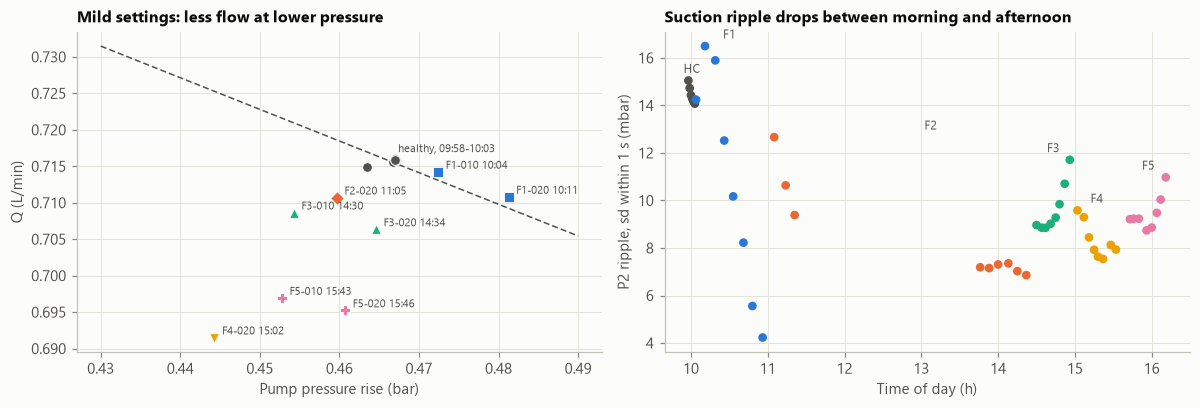

In [10]:
pl_mean = runs[runs["condition"] == "HC"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for _, r in mild.iterrows():
    c = r["condition"]
    ax.scatter(r["dP_pump"], r["Q"], color=pl.CONDITION_COLORS[c], marker=pl.CONDITION_MARKERS[c], s=40, zorder=3,
               edgecolor=pl.SURFACE, linewidth=0.6)
    if c != "HC":
        ax.annotate(f"{r['run_id']} {r['clock']}", (r["dP_pump"], r["Q"]), xytext=(5, 2), textcoords="offset points",
                    fontsize=7.5, color=pl.INK_2)
ax.annotate("healthy, 09:58-10:03", (pl_mean["dP_pump"].mean(), pl_mean["Q"].mean()), xytext=(5, 6),
            textcoords="offset points", fontsize=7.5, color=pl.INK_2)
dpz = np.linspace(0.43, 0.49, 10)
ax.plot(dpz, models["all"].pump.q(dpz) - models["all"].pump.q(pl_mean["dP_pump"].mean()) + pl_mean["Q"].mean(),
        color=pl.INK_2, lw=1, ls=(0, (4, 2)))
ax.set_xlabel("Pump pressure rise (bar)")
ax.set_ylabel("Q (L/min)")
ax.set_title("Mild settings: less flow at lower pressure")
ax = axes[1]
allr = runs.copy()
ax.scatter(allr["clock"].dt.hour + allr["clock"].dt.minute / 60, allr["P2_std"] * 1000,
           c=[pl.CONDITION_COLORS[c] for c in allr["condition"]], s=22, zorder=3)
for f in config.CONDITIONS:
    r = allr[allr["condition"] == f]
    ax.annotate(f, (r["clock"].dt.hour.mean() + r["clock"].dt.minute.mean() / 60, r["P2_std"].max() * 1000),
                xytext=(0, 5), textcoords="offset points", ha="center", fontsize=8, color=pl.INK_2)
ax.set_xlabel("Time of day (h)")
ax.set_ylabel("P2 ripple, sd within 1 s (mbar)")
ax.set_title("Suction ripple drops between morning and afternoon")
fig.tight_layout()
pl.save(fig, "03_afternoon_drift")
plt.show()

Three independent signs that the healthy system itself changed between 10:00 and the afternoon:

1. **Flow per revolution fell by 1-3.5 %** at the mildest afternoon settings, while the pump's pressure
   rise also fell. A fault that only restricts the line moves the point *along* the pump curve (more
   pressure, less flow); here both fell, so the pump curve itself moved down.
2. **The suction-side ripple fell by about 30 %** (P1/P2 sd from 13-15 mbar to about 9 mbar) for every
   afternoon recording, whatever the fault.
3. **P1 kept drifting** (tank level), continuing the trend inside the healthy runs.

The most likely cause is the water warming up as the rig ran: lower viscosity increases internal
slip in a gear pump (less flow at a given pressure) and changes the damping of the pressure ripple.
Bardakis (2019) observed exactly this sensitivity on the later rig and only tested at thermal
equilibrium for that reason. Temperature was never measured here, so the cause cannot be confirmed;
what can be said is that **a change of a few percent in pump delivery is within normal operation of this rig over
a day**, and that is the same size as the mildest pump and leak faults.

Practical consequences: the morning healthy envelope cannot be used in the afternoon; the pump
residual of the twin must allow for this drift (its limit is calibrated across the day); and a digital
twin of this rig needs a fluid-temperature input (notebook 06).

## 7. Does the lecture's diagnostic tree work on this data?

Diagnostic Trees page 9 decides with P3 (up or down), then P4, then fixed P3 bands (1.10-1.15 bar ->
FM2, 1.15-1.20 bar -> FM1). Applied here with the healthy envelope deciding "up" and "down":

In [11]:
tree = dg.tutor_tree(w, base.mean, base.sd_total)
tt = (pd.DataFrame({"condition": w["condition"], "severity": w["severity"], "tree": tree})
      .groupby(["condition", "severity"])["tree"].agg(lambda s: s.value_counts().index[0]).unstack(0))
tt = tt[[c for c in config.CONDITIONS if c in tt]]
tt.to_csv(config.TABLE_DIR / "03_lecture_tree_results.csv")
tt.fillna("")

condition,HC,F1,F2,F3,F4,F5
severity,,,,,,
0.0,HC,,,,,
10.0,,"detected, not isolated",,F1/F2/F4,,F1/F2/F4
20.0,,F1/F2/F4,F1/F2/F4,"detected, not isolated",F1/F2/F4,F1/F2/F4
30.0,,F1/F2/F4,F1/F2/F4,F3,F1/F2/F4,"detected, not isolated"
40.0,,F1/F2/F4,F1,F3,F1/F2/F4,F5
50.0,,F1/F2/F4,F2,F3,F1/F2/F4,F5
60.0,,F1/F2/F4,F1/F2/F4,F3,F1,F5
70.0,,F1/F2/F4,F1/F2/F4,F3,F1,F5
80.0,,F1/F2/F4,F1/F2/F4,F3,F1,F5


* It isolates **F3 and F5 from 30-40 % travel**, as designed.
* F1, F2 and F4 stay in the **F1/F2/F4 ambiguity group** almost everywhere. The fixed P3 bands do not
  transfer: they belong to a different operating point, and here they send the strongest leaks to F1.
* The mildest F3 and F5 settings are sent to the F1/F2/F4 group because P3 *fell* (the afternoon
  drift) before the blockage raised it.

The physics residuals in section 4 resolve the ambiguity group with the same sensors; notebook 04
measures how far each approach really generalises.

## 8. Physical severity versus valve travel

Valve travel is a control setting. The residuals give a physical severity instead: the resistance
ratio of the blocked section (F1, F3, F5) or the share of pump delivery lost (F2, F4).

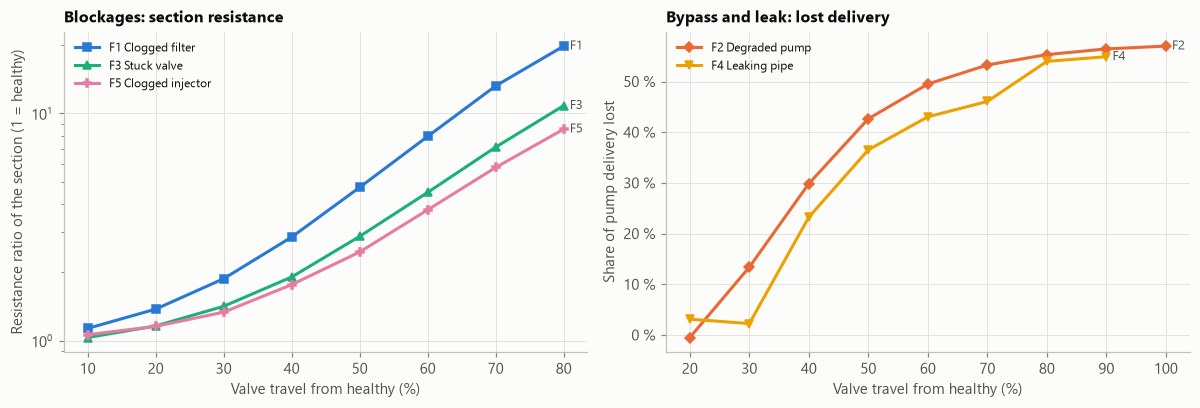

In [12]:
sev_phys = pd.Series(np.nan, index=res_runs.index)
for f, col in {"F1": "r_filter", "F3": "r_valve", "F5": "r_nozzle"}.items():
    m = res_runs["condition"] == f
    sev_phys[m] = 1 + res_runs.loc[m, col]
for f in ("F2", "F4"):
    m = res_runs["condition"] == f
    sev_phys[m] = res_runs.loc[m, "r_pump"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for f in FAULTS:
    m = res_runs["condition"] == f
    ax = axes[0] if f in ("F1", "F3", "F5") else axes[1]
    ax.plot(res_runs.loc[m, "severity"], sev_phys[m], color=pl.CONDITION_COLORS[f], marker=pl.CONDITION_MARKERS[f],
            ms=5, label=f"{f} {config.CONDITION_NAMES[f]}")
    pl.label_end(ax, res_runs.loc[m, "severity"].iloc[-1], sev_phys[m].iloc[-1], f)
axes[0].set_yscale("log")
axes[0].set_ylabel("Resistance ratio of the section (1 = healthy)")
axes[0].set_title("Blockages: section resistance")
axes[1].set_ylabel("Share of pump delivery lost")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f} %"))
axes[1].set_title("Bypass and leak: lost delivery")
for ax in axes:
    ax.set_xlabel("Valve travel from healthy (%)")
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
pl.save(fig, "03_physical_severity")
plt.show()

* Blockage resistance grows roughly **exponentially** with valve travel: a filter at 80 % travel has
  about 20 times its healthy resistance, a stuck valve about 11 times, the nozzle about 8.5 times.
  The first 10-20 % of travel adds only 5-15 % resistance, which is why mild settings are hard to see.
* The bypass and leak valves are **dead below about 30-35 %** and then open quickly; at full travel more
  than half of the pump's delivery never reaches the end of the line.

## Summary for Task 3

* Each fault has a recognisable signature, but raw pressures leave filter, pump and leak faults
  ambiguous (as in the lecture tree). Section pressure-drop residuals, built from the rig layout and
  fitted without the fault being scored, separate all five.
* Blockages move the operating point along the pump curve; lost-delivery faults move it below.
* Three settings (F2 20 %, F4 20 % and 30 %) produce no physical change and should not be counted as
  detectable faults.
* The healthy system drifts through the day by about as much as the mildest faults, and the recording
  schedule ties that drift to the fault labels. That is the dominant limit on what this dataset can
  prove about early detection.